# Emmons Glacier Control
Post Steady State with no change to SMB

In [1]:
import geojson
import geopandas as gpd
import rasterio
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import firedrake
from firedrake import Constant, inner, jump, grad, dx, avg, dS, min_value, max_value, conditional, pi
import icepack
from matplotlib.colors import LinearSegmentedColormap
import irksome
from irksome import Dt
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator, FormatStrFormatter)
import matplotlib.colors as col
from tqdm.notebook import trange, tqdm

## Read In Initialization Checkpoints

In [2]:
filename = "../Checkpoints/emmons_short_inflowchange.h5"

with firedrake.CheckpointFile(filename, "r") as chk:
    mesh = chk.load_mesh()
    timesteps = np.array(chk.h5pyfile["timestep"])
    b_read = chk.load_function(mesh, name="bed", idx=len(timesteps) - 1)
    w = chk.load_function(mesh, name="mono", idx=len(timesteps) - 1)

In [3]:
u_read, M_read, τ_read, h_read = firedrake.split(w)

## Velocity Data

In [4]:
outline_filename = '../../../data/emmons_outine/emmons_1896_mod.geojson'

quinn_velo = '../../../data/Velocity/quinn_velo/s2/S2_all_median_horizontal_velocity.tif'
quinn_WinVelo = '../../../data/Velocity/quinn_velo/s2/S2_NDJFM_median_horizontal_velocity.tif'
quinn_SumVelo = '../../../data/Velocity/quinn_velo/s2/S2_MJJAS_median_horizontal_velocity.tif'

In [5]:
with open(outline_filename, "r") as outline_file:
    outline = geojson.load(outline_file)

In [6]:
δ = 0.0

coords = np.array(list(geojson.utils.coords(outline)))
xmin, xmax = coords[:, 0].min() - δ, coords[:, 0].max() + δ
ymin, ymax = coords[:, 1].min() - δ, coords[:, 1].max() + δ

print(f'Outline Bbox: left={xmin}, bottom={ymin}, right={xmax}, top={ymax}')

Outline Bbox: left=594790.788972, bottom=5188892.145092, right=601987.779641, top=5195038.951454


In [7]:
extent = {
    "left": coords[:, 0].min() - 1,
    "right": coords[:, 0].max(),
    "bottom": coords[:, 1].min(),
    "top": coords[:, 1].max(),
}

In [8]:
# Velocity Files
velo_file = rasterio.open(quinn_velo)
window = rasterio.windows.from_bounds(**extent, 
                                      transform=velo_file.transform).round_lengths().round_offsets()
transform = velo_file.window_transform(window)
medVelo_obs = velo_file.read(window=window)

velo_file1 = rasterio.open(quinn_WinVelo)
window1 = rasterio.windows.from_bounds(**extent, 
                                      transform=velo_file1.transform).round_lengths().round_offsets()
transform1 = velo_file1.window_transform(window1)
WinVelo_obs = velo_file1.read(window=window1)

velo_file2 = rasterio.open(quinn_SumVelo)
window2 = rasterio.windows.from_bounds(**extent, 
                                      transform=velo_file1.transform).round_lengths().round_offsets()
transform2 = velo_file2.window_transform(window2)
SumVelo_obs = velo_file2.read(window=window2)

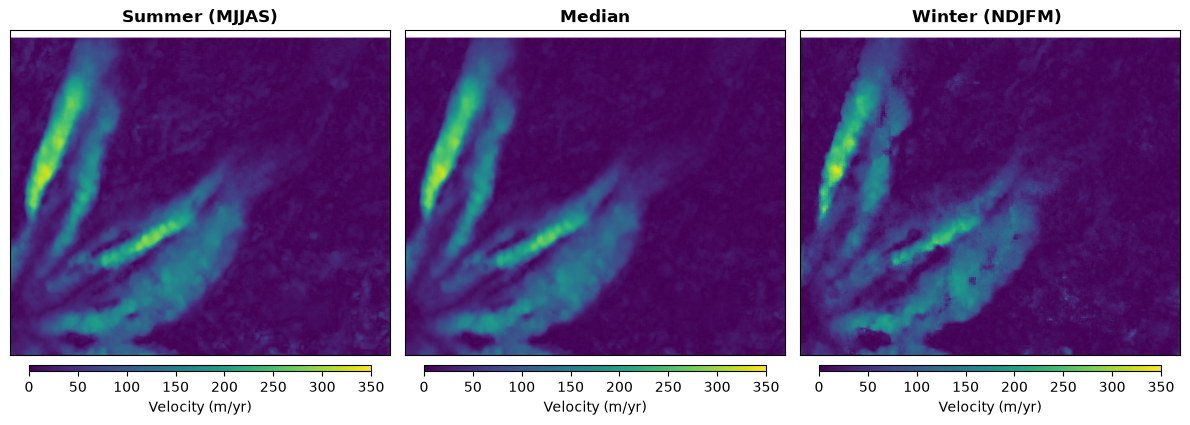

In [9]:
fig, ax = plt.subplots(1, 3, figsize = [12, 10], sharey = True)
colors = ax[0].imshow(SumVelo_obs[0, :, :], 
                      extent=(extent["left"], extent["right"], extent["bottom"], extent["top"]),
                      vmax = 350,
                      axes=ax[0])
fig.colorbar(colors, label="Velocity (m/yr)", 
                      orientation = 'horizontal', 
                      shrink=0.9, 
                      pad = 0.01, 
                      aspect=50)
                      #axes = ax[0])
ax[0].set_title('Summer (MJJAS)', fontweight = 'bold')
ax[0].set_aspect("equal")
ax[0].set_xticks([])
ax[0].set_yticks([])

colors1 = ax[1].imshow(medVelo_obs[0, :, :], 
                      vmax = 350,
                      extent=(extent["left"], extent["right"], extent["bottom"], extent["top"]),
                      axes=ax[1])
fig.colorbar(colors1, label="Velocity (m/yr)",                           
                      orientation = 'horizontal', 
                      shrink=0.9, 
                      pad = 0.01, 
                      aspect=50)
ax[1].set_title('Median', fontweight = 'bold')
ax[1].set_aspect("equal")
ax[1].set_xticks([])
ax[1].set_yticks([])

colors1 = ax[2].imshow(WinVelo_obs[0, :, :], 
                      vmax = 350,
                      extent=(extent["left"], extent["right"], extent["bottom"], extent["top"]),
                      axes=ax[2])
fig.colorbar(colors1, label="Velocity (m/yr)",                           
                      orientation = 'horizontal', 
                      shrink=0.9, 
                      pad = 0.01, 
                      aspect=50)
ax[2].set_title('Winter (NDJFM) ', fontweight = 'bold')
ax[2].set_aspect("equal")
ax[2].set_xticks([])
ax[2].set_yticks([])

fig.tight_layout()

## Mesh and Function Space Generation

In [10]:
## Function Spaces
dg0 = firedrake.FiniteElement("DG", "triangle", 0)
dg1 = firedrake.FiniteElement("DG", "triangle", 1)
cg1 = firedrake.FiniteElement("CG", "triangle", 1)

V = firedrake.VectorFunctionSpace(mesh, cg1)
Q = firedrake.FunctionSpace(mesh, cg1) 

## Projecting onto Mesh

In [11]:
def smoove(q_obs, λ):
    q = q_obs.copy(deepcopy=True)
    J = 0.5 * ((q - q_obs)**2 + Constant(λ)**2 * inner(grad(q), grad(q))) * dx
    F = firedrake.derivative(J, q)
    bc = firedrake.DirichletBC(q.function_space(), q_obs, "on_boundary")
    firedrake.solve(F == 0, q, bc)
    return q

def fix_obs(field, file):
    ny, nx = field.shape
    bound_loc = file.bounds
    
    xh = np.linspace(bound_loc.left, bound_loc.right, nx)
    yh = np.linspace(bound_loc.bottom, bound_loc.top, ny)[::-1]

    return xr.DataArray(
        field,
        dims=("y", "x"),
        coords={"x": xh, "y": yh},
    )


λ = 900.0

In [12]:
v_d = fix_obs(SumVelo_obs[0, :, :], velo_file)
v_o = icepack.interpolate(v_d, Q, method="nearest")
vs0 = v_o.copy(deepcopy = True)

v_d = fix_obs(WinVelo_obs[0, :, :], velo_file)
v_o = icepack.interpolate(v_d, Q, method="nearest")
vw0 = v_o.copy(deepcopy = True)

v_d = fix_obs(medVelo_obs[0, :, :], velo_file)
v_o = icepack.interpolate(v_d, Q, method="nearest")
vm0 = v_o.copy(deepcopy = True)

## Initial Solves (SIA and Hybrid)
Useful for troubleshooting model initialization issues

In [13]:
h_read = firedrake.project(h_read, Q)

In [14]:
from icepack2.constants import gravity, ice_density, glen_flow_law
A = icepack.rate_factor(Constant(279.15)) 

print(f'Enhancement Factor: {icepack.rate_factor(279.15) / icepack.rate_factor(273.15)}') # enhancement factor

h = h_read.copy(deepcopy = True)
s_read = h + b_read
s = firedrake.project(s_read, Q)
s0 = s#.copy(deepcopy = True)

Enhancement Factor: 3.726638696289609


In [15]:
from icepack2.constants import gravity as g, ice_density as ρ_I, glen_flow_law, water_density as ρ_W

# Method for DG0 surface
ρ = Constant(ρ_I)
g = Constant(g)
ρ_W = Constant(ρ_W)

τ_d = firedrake.Function(V)
σ = firedrake.TestFunction(V)
ν = firedrake.FacetNormal(mesh)

F_cells = (inner(τ_d, σ) + ρ*g*h * inner(grad(s0), σ)) * dx
F_facets = -inner(avg(ρ*g*h) * jump(s0, ν), avg(σ)) * dS
F = F_cells + F_facets

firedrake.solve(F == 0, τ_d)

In [16]:
n = Constant(glen_flow_law)

u_sia = firedrake.Function(V)
v = firedrake.TestFunction(V)

u_shear = (-2/(n+2)) * h * A * (inner(τ_d, τ_d) ** 0.5) ** (n-1) * τ_d
F = inner(u_sia - u_shear, v) * dx

solver_params = {"snes_type": "ksponly", "ksp_type": "gmres"}
fc_params = {"quadrature_degree": 6}
params = {"solver_parameters": solver_params, "form_compiler_parameters": fc_params}
firedrake.solve(F == 0, u_sia, **params)

In [17]:
u = firedrake.Function(V)

Σ = firedrake.TensorFunctionSpace(mesh, dg0, symmetry=True)
T = firedrake.VectorFunctionSpace(mesh, cg1)
Z = V * Σ * T
z = firedrake.Function(Z)

z.sub(0).assign(u);

In [18]:
s = s0.copy(deepcopy = True)
b = b_read.copy(deepcopy = True)

In [19]:
τ_c = Constant(0.1) # Critical Stress (set to 0.1 mPa)
ε_c = Constant(A * τ_c ** n) # multiply by very small Λ for SIA-like

K = h * A / (n + 2)

t = Constant(0.0)
U_0 = Constant(20.0)
ΔU = Constant(15.0)

U_c = U_0 + ΔU * firedrake.sin(2 * pi * t)# + ϕ) # Critical velocity -> 0 completely turns of long. stress (SIA-like) 100
#U_c = Constant(8.0) 
u_c = K * τ_c ** n + U_c

In [20]:
glen_rheology = {
    "flow_law_exponent": n,
    "flow_law_coefficient": ε_c / τ_c ** n,
    "sliding_exponent": n,
    "sliding_coefficient": u_c / τ_c ** n,
}

α = firedrake.Constant(1e-4)
linear_rheology = {
    "flow_law_exponent": 1,
    "flow_law_coefficient": ε_c / τ_c,
    "sliding_exponent": 1,
    "sliding_coefficient": u_c / τ_c,
}

u, M, τ = firedrake.split(z)
fields = {
    "velocity": u,
    "membrane_stress": M,
    "basal_stress": τ,
    "thickness": h,
    "surface": s,
}

v, N, σ = firedrake.TestFunctions(Z)

In [21]:
degree = 1
qdegree = max(8, degree ** glen_flow_law)
inflow_ids = [1]
#side_wall_ids = [1, 3]
bc = firedrake.DirichletBC(Z.sub(0), Constant((5.0, 11.0)), inflow_ids)# -----> Inflow set to some velocity prof 5.0, 11.0
pparams = {
    "bcs": bc,
    "form_compiler_parameters": {"quadrature_degree": qdegree},
}

sparams = {
    "solver_parameters": {
        "snes_monitor": None,
        #"snes_linesearch_monitor": None,
        "snes_type": "newtonls",
        "snes_max_it": 200,
        "snes_divergence_tolerance": 1e250,
        "snes_linesearch_type": "secant",
        "snes_linesearch_max_it": 5,
        "ksp_type": "gmres",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    },
}

In [22]:
from icepack2 import model
from icepack2.model.variational import momentum_balance, flow_law, friction_law

H = Constant(100.0)

F = (
    momentum_balance(**fields, test_function=v)
    + firedrake.replace(flow_law(**fields, **glen_rheology, test_function=N), {h: H})
    + α * firedrake.replace(flow_law(**fields, **linear_rheology, test_function=N), {h: H})
    + friction_law(**fields, **glen_rheology, test_function=σ)
    + α * friction_law(**fields, **linear_rheology, test_function=σ)
)

momentum_problem = firedrake.NonlinearVariationalProblem(F, z, **pparams)
momentum_solver = firedrake.NonlinearVariationalSolver(momentum_problem, **sparams)

In [23]:
num_continuation_steps = 10
for exponent in np.linspace(1.0, 3.0, num_continuation_steps):
    n.assign(exponent)
    momentum_solver.solve()

  0 SNES Function norm 2.920631553226e+05
  1 SNES Function norm 4.818328361549e-07
  0 SNES Function norm 8.594998817730e+08
  1 SNES Function norm 8.602205199339e+06
  2 SNES Function norm 1.005427592621e+05
  3 SNES Function norm 2.673850160791e+03
  4 SNES Function norm 9.501577257872e+00
  5 SNES Function norm 1.921926174126e-04
  0 SNES Function norm 5.711756126970e+08
  1 SNES Function norm 6.693431493523e+06
  2 SNES Function norm 1.188701460260e+05
  3 SNES Function norm 2.247339408470e+03
  4 SNES Function norm 9.269440279885e+00
  5 SNES Function norm 2.143021739135e-04
  0 SNES Function norm 3.774660270425e+08
  1 SNES Function norm 4.343402606007e+06
  2 SNES Function norm 6.867657063114e+04
  3 SNES Function norm 9.595341335005e+01
  4 SNES Function norm 4.196711923197e-03
  0 SNES Function norm 2.483690740756e+08
  1 SNES Function norm 2.605253503584e+06
  2 SNES Function norm 3.720048101190e+04
  3 SNES Function norm 9.532513031610e+01
  4 SNES Function norm 2.239156110

In [24]:
u_init, M_init, τ_init = z.subfunctions
u_init.dat.data_ro.max()

np.float64(387.3266128150919)

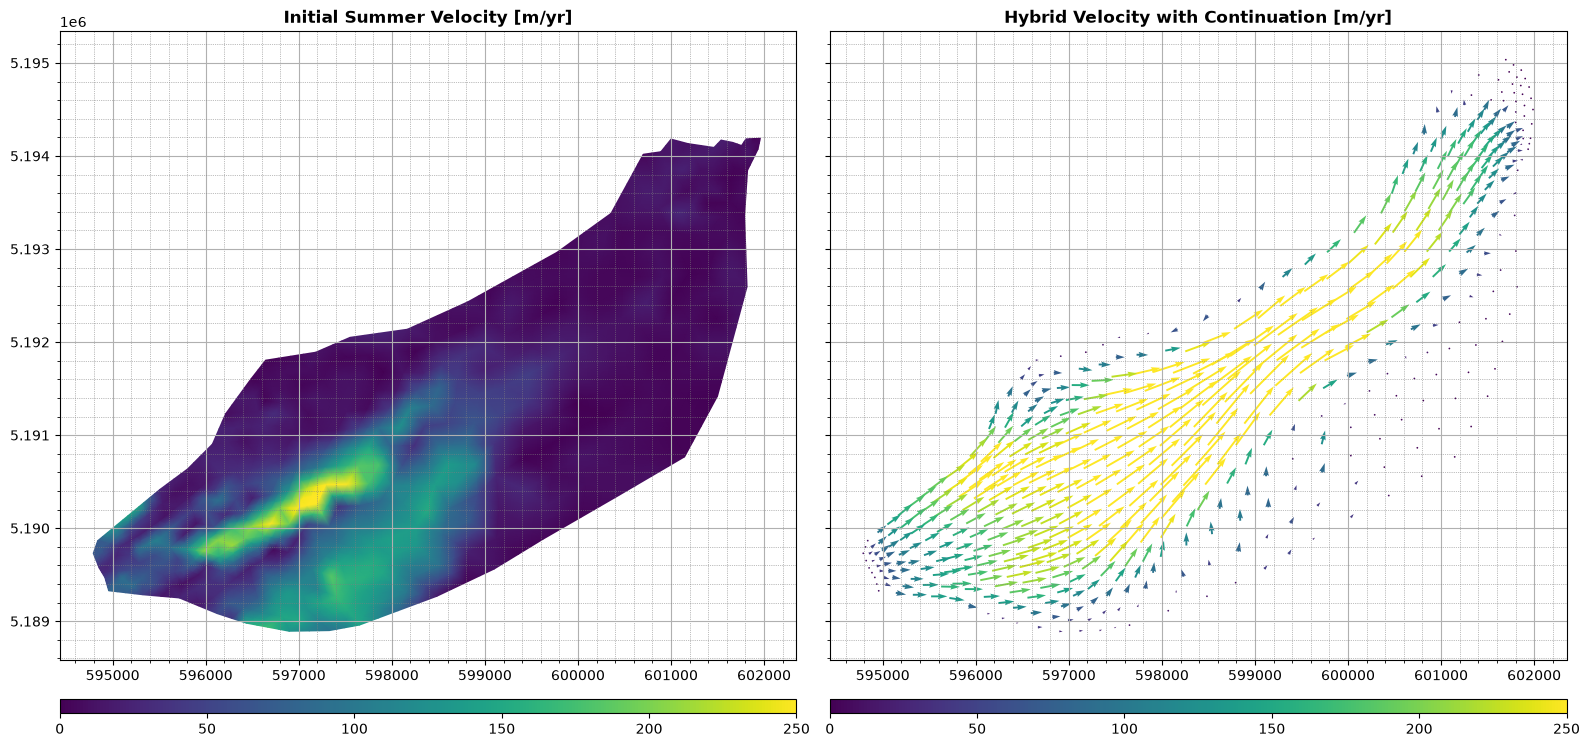

In [25]:
norm = col.Normalize(vmin=0., vmax=250)

fig, axes = plt.subplots(1, 2, figsize = (16, 10), sharex = True, sharey = True)

axes[0].set_aspect("equal")
init_vel = firedrake.tripcolor(vs0, 
                             vmin = 0,
                             vmax = 250, 
                             axes=axes[0])
fig.colorbar(init_vel, fraction=0.046, pad=0.04, orientation = 'horizontal', aspect=50)
axes[0].set_title('Initial Summer Velocity [m/yr]', fontweight = 'bold')
axes[0].xaxis.set_minor_locator(AutoMinorLocator())
axes[0].tick_params(which='both')
axes[0].tick_params(which='major')
axes[0].tick_params(which='minor')
axes[0].yaxis.set_minor_locator(AutoMinorLocator())

axes[0].grid()
axes[0].grid(which='minor', linestyle=':', linewidth='0.5', color='gray')

axes[1].set_aspect("equal")
calc_vel = firedrake.quiver(u_init, 
                             #cmap = cmap2,  
                             norm = norm, 
                             axes=axes[1])

fig.colorbar(calc_vel, fraction=0.046, pad=0.04, orientation = 'horizontal',aspect=50)
axes[1].set_title('Hybrid Velocity with Continuation [m/yr]', fontweight = 'bold')
axes[1].xaxis.set_minor_locator(AutoMinorLocator())
axes[1].tick_params(which='both')
axes[1].tick_params(which='major')
axes[1].tick_params(which='minor')
axes[1].yaxis.set_minor_locator(AutoMinorLocator())

axes[1].grid()
axes[1].grid(which='minor', linestyle=':', linewidth='0.5', color='gray')

fig.tight_layout()

## Generating an SMB Field
Super basic field w/o debris cover or wind scour

In [26]:
## Pull relevant state vars
s_min = s.dat.data_ro.min()
s_max = s.dat.data_ro.max()
s_diff = int(np.round(s_max - s_min))

s_vals = np.linspace(s_min, s_max, s_diff)
a_vals = np.zeros(s_diff)

In [27]:
# Set the breakpoints & associated mass balance
a_max = 7
ela = 3200

z = [s_min, ela, s_max] #[s0, ela OR wind_elev, smax]
b_dot = [-10, 4, a_max] # [b_t, b_max, a_max OR wind scour]

windS_elev = z[1]

# Slope calculations
m1 = (b_dot[1] - b_dot[0]) / (z[1] - z[0])         # Normal da/dz
y1_int = b_dot[1] - m1 * z[1]

m2 = (b_dot[2] - b_dot[1]) / (z[2] - z[1])         # Wind scour da/dz
y2_int = b_dot[2] - m2 * z[2]

In [28]:
# Actual expression for the SMB
expr2 = conditional(                               # Below wind scour
    windS_elev >= s,
    (m1 * s) + y1_int,
    0,
)

expr = conditional(                                # Above wind scour
    windS_elev < s,                                 #condition
    min_value(a_max, y2_int + (m2 * s)),
    expr2,                                          # false val
)

# Wrapping it into a function 
def smb2(s):
    return expr

a = firedrake.Function(Q).interpolate(smb2(s))
a.dat.data_ro.sum()

np.float64(-569.9483954893085)

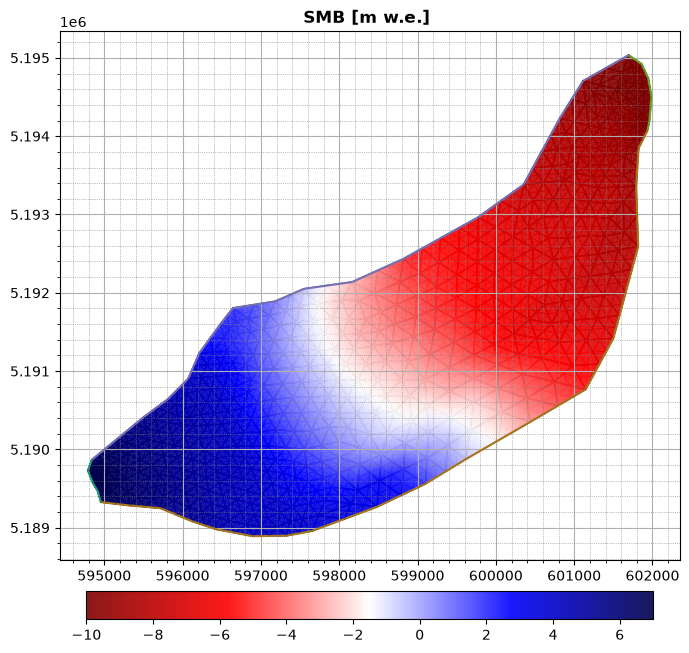

In [29]:
fig, axes = plt.subplots(figsize = (8, 8), sharex = True, sharey = True)

axes.set_aspect("equal")
firedrake.triplot(mesh,
                  axes=axes)
colors = firedrake.tripcolor(a, 
                             #vmin = -10, vmax = 10,
                             alpha = 0.9, 
                             cmap = 'seismic_r',
                             axes=axes)

fig.colorbar(colors, fraction=0.046, pad=0.05, orientation = 'horizontal')
axes.set_title('SMB [m w.e.] ', fontweight = 'bold')

axes.xaxis.set_minor_locator(AutoMinorLocator())
axes.tick_params(which='both')
axes.tick_params(which='major')
axes.tick_params(which='minor')
axes.yaxis.set_minor_locator(AutoMinorLocator())

axes.grid()
axes.grid(which='minor', linestyle=':', linewidth='0.5', color='gray')

## Run Params

In [30]:
W = V * Σ * T * Q

w = firedrake.Function(W)

w.sub(0).assign(u_init)
w.sub(1).assign(M_init)
w.sub(2).assign(τ_init)
w.sub(3).assign(h);

In [31]:
u, M, τ, h = firedrake.split(w)
v, N, σ, η = firedrake.TestFunctions(W)

Γ = 1e-4

fields = {
    "velocity": u,
    "membrane_stress": M,
    "basal_stress": τ,
    "thickness": h,
    "surface": b + h,
}

F_momentum = (
    momentum_balance(**fields, test_function=v)
    + firedrake.replace(flow_law(**fields, **glen_rheology, test_function=N), {h: H})
    + α * firedrake.replace(flow_law(**fields, **linear_rheology, test_function=N), {h: H})
    + friction_law(**fields, **glen_rheology, test_function=σ)
    + α * friction_law(**fields, **linear_rheology, test_function=σ)
)

F_mass = model.mass_balance(thickness=h, velocity=u, accumulation=a, test_function=η)

F = F_momentum + F_mass

In [32]:
tableau = irksome.BackwardEuler()
dt = Constant(1.0/365.25)

lower = firedrake.Function(W)
upper = firedrake.Function(W)
lower.assign(-np.inf)
upper.assign(+np.inf)
lower.subfunctions[3].assign(0.0)
bounds = ("stage", lower, upper)

vparams = {
    "snes_monitor": None, #":emmons-output-vi.log",
    "snes_linesearch_monitor": None,
    "snes_type": "vinewtonrsls",
    "snes_max_it": 200,
    "snes_divergence_tolerance": 1e250,
    "snes_linesearch_type": "secant", # or "nleqerr" OR "bt"
    #"snes_linesearch_order": 1,
    "snes_linesearch_max_it": 60,
    "ksp_type": "gmres",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps",
}

bc = firedrake.DirichletBC(W.sub(0), Constant((0, 0)), inflow_ids)# + side_wall_ids)

bparams = {
    "solver_parameters": vparams,
    "form_compiler_parameters": fc_params,
    "stage_type": "value",
    "basis_type": "Bernstein",
    "bounds": bounds,
}

solver = irksome.TimeStepper(F, tableau, t, dt, w, **bparams)

/opt/firedrake/firedrake/function.py:575: FutureWarning: The ``Function.at`` method is deprecated and will be removed in a future release. Please use the ``PointEvaluator`` class instead.
  warnings.warn(


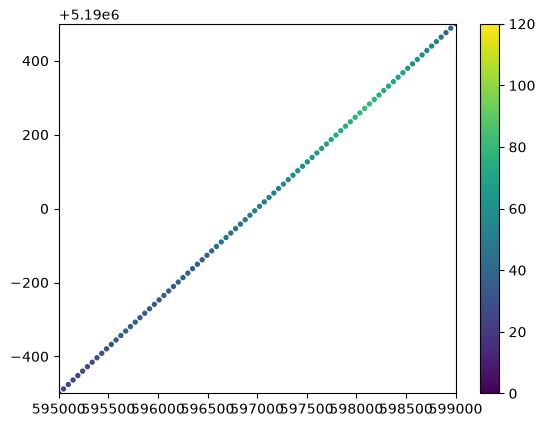

In [33]:
def interpolate_points(x1, y1, x2, y2, interval):
    distance = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    n = int(np.ceil(distance / interval))

    x = np.linspace(x1, x2, n + 1)
    y = np.linspace(y1, y2, n + 1)

    points = np.column_stack((x, y))

    return points

xs = interpolate_points(595000, 5.1895e6, 
                        599000, 5.1905e6, 
                        50)

evals = h_read.at(xs)

vals = plt.scatter(xs[:, 0], xs[:, 1], c = evals, 
                   s = 8,
                  vmin = 0, vmax = 120
                  )
plt.xlim(595000, 599000)
plt.ylim(5.1895e6, 5.1905e6)

plt.colorbar(vals)

In [34]:
min(evals)

array(21.45305035)

In [35]:
# Growth Run w/ no debris
us = [w.subfunctions[0].copy(deepcopy=True)]
hs = [w.subfunctions[3].copy(deepcopy=True)]
a_s = []
Uc_list = []

dt.assign(1.0/12)
final_time = 200.0
num_steps = int(final_time / float(dt))
timesteps = np.linspace(0, final_time, num_steps + 1)
for step in trange(num_steps):
        
    s.interpolate(b + h) 
    
    solver.advance()
    h = w.subfunctions[3]
    a.interpolate(smb2(b + h))
    t.assign(t + dt)
        
    us.append(w.subfunctions[0].copy(deepcopy=True))
    hs.append(w.subfunctions[3].copy(deepcopy=True))
    a_s.append(a.copy(deepcopy=True))
    Uc_list.append(float(U_c))

  0%|          | 0/240 [00:00<?, ?it/s]

  0 SNES Function norm 4.262045268079e+06
      Line search: lambdas = [1., 0.5, 0.], fnorms = [80307.6, 2.13082e+06, 4.26205e+06]      Line search: lambdas = [0.999374, 0.999687, 1.], fnorms = [80410., 80347.8, 80307.6]      Line search terminated: lambda = 0.999374, fnorm = 80410.
  1 SNES Function norm 8.041003619475e+04
      Line search: lambdas = [1., 0.5, 0.], fnorms = [14955.5, 43481.3, 80410.      Line search terminated: lambda = 1., fnorm = 14955.5
  2 SNES Function norm 1.495548672437e+04
      Line search: lambdas = [1., 0.5, 0.], fnorms = [1979.94, 7968.78, 14955.5]      Line search terminated: lambda = 1., fnorm = 1979.94
  3 SNES Function norm 1.979938327409e+03
      Line search: lambdas = [1., 0.5, 0.], fnorms = [92.7522, 1011.06, 1979.94]      Line search terminated: lambda = 1., fnorm = 92.7522
  4 SNES Function norm 9.275216651691e+01
      Line search: lambdas = [1., 0.5, 0.], fnorms = [0.496388, 46.4836, 92.7522]      Line search terminated: lambda = 1., fnorm = 0

In [36]:
# Calculate volume and mass added through time

volumes = np.array([firedrake.assemble(h*dx) / 1e9 for h in hs])
mass_b = np.array([firedrake.assemble(a*dx) for a in a_s])

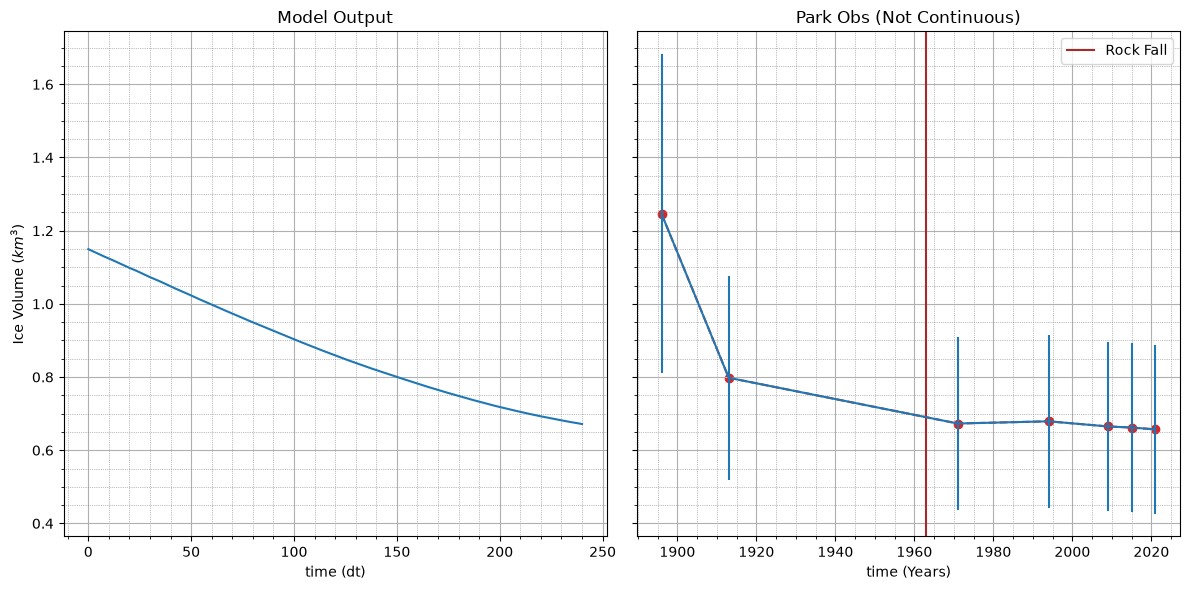

In [37]:
# Park Data Comparison 
## Data source MORA 23 table 14

park_date = [1896, 1913, 1971, 1994, 2009, 2015, 2021] # year
park_vol = [1.246, 0.798, 0.673, 0.679, 0.665, 0.662, 0.657] # km^3
vol_errors = [0.436, 0.279, 0.236, 0.237, 0.230, 0.232, 0.230]

fig, ax = plt.subplots(1, 2, figsize = (12, 6), sharey = True)
color = 'tab:blue'
ax[0].set_title('Model Output')
ax[0].set_xlabel('time (dt)')
ax[0].set_ylabel("Ice Volume ($km^3$)")
ax[0].plot(volumes, color=color)
ax[0].tick_params(axis='y')

ax[0].xaxis.set_minor_locator(AutoMinorLocator())
ax[0].tick_params(which='both')
ax[0].tick_params(which='major')
ax[0].tick_params(which='minor')
ax[0].yaxis.set_minor_locator(AutoMinorLocator())

ax[0].grid()
ax[0].grid(which='minor', linestyle=':', linewidth='0.5', color='gray')

color = 'tab:red'
ax[1].set_title('Park Obs (Not Continuous)')
ax[1].set_xlabel('time (Years)')
ax[1].axvline(x = 1963, color = 'brown', label = 'Rock Fall')
ax[1].plot(park_date, park_vol, color=color, linestyle ='--')
ax[1].scatter(park_date, park_vol, color=color)
ax[1].errorbar(park_date, park_vol,
               yerr = vol_errors)
ax[1].tick_params(axis='y', labelcolor=color)
ax[1].legend()

ax[1].xaxis.set_minor_locator(AutoMinorLocator())
ax[1].tick_params(which='both')
ax[1].tick_params(which='major')
ax[1].tick_params(which='minor')
ax[1].yaxis.set_minor_locator(AutoMinorLocator())

ax[1].grid()
ax[1].grid(which='minor', linestyle=':', linewidth='0.5', color='gray')

fig.tight_layout()

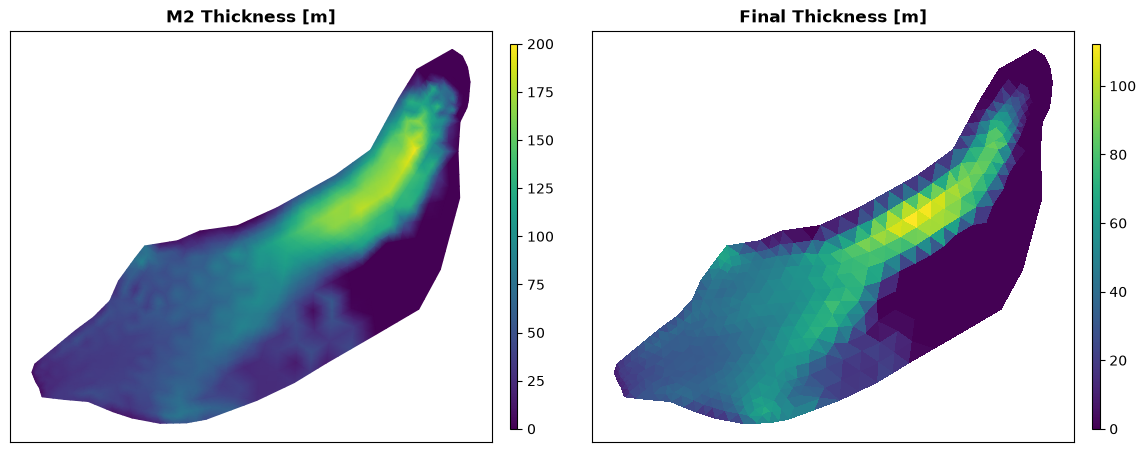

In [38]:
# Final Thickness check to see where 0 thickness exists
fig, axes = plt.subplots(1, 2, figsize = (12,8))

init = firedrake.tripcolor(h_read, 
                      vmin = 0, 
                      vmax = 200,                        
                      axes=axes[0])
fig.colorbar(init, location = 'right',                           
             shrink=0.5, 
                          pad = 0.03, 
                          aspect=50)
axes[0].set_title('M2 Thickness [m]', fontweight = 'bold')
axes[0].set_aspect("equal")
axes[0].set_xticks([])
axes[0].set_yticks([])

axes[1].set_title('Final Thickness [m]', fontweight = 'bold')
axes[1].set_aspect("equal")
fin = firedrake.tripcolor(hs[-1], 
                             num_sample_points=1, 
                             vmin = 0,
                             #vmax = 200,
                             shading="flat", 
                             axes=axes[1])
fig.colorbar(fin, 
                          orientation = 'vertical', 
                          shrink=0.5, 
                          pad = 0.03, 
                          aspect=50)
axes[1].set_aspect("equal")
axes[1].set_xticks([])
axes[1].set_yticks([])

plt.tight_layout()

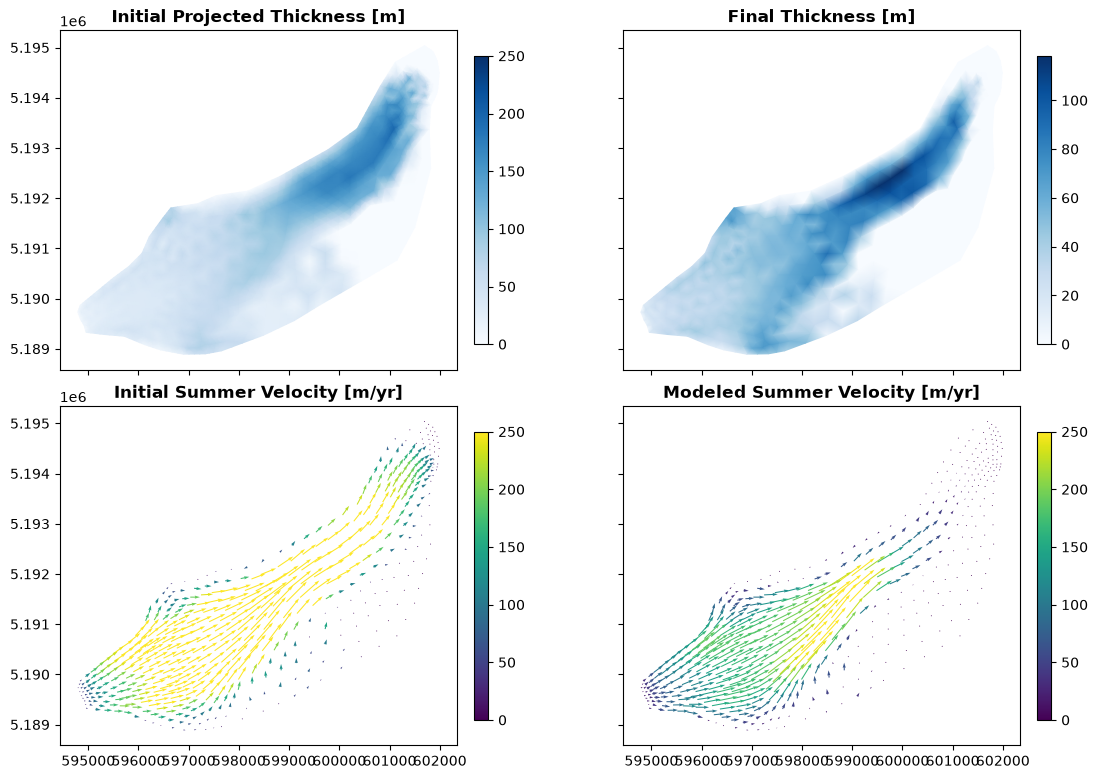

In [39]:
# XY Thickness Plots
norm = col.Normalize(vmin=0., vmax=250)

fig, axes = plt.subplots(2, 2, figsize = (12,8), sharex = True, sharey = True)
# P1
axes[0, 0].set_title('Initial Projected Thickness [m]', fontweight = 'bold')
axes[0, 0].set_aspect("equal")
thick = firedrake.tripcolor(h_read,
                             cmap = 'Blues',
                             vmin = 0,
                             vmax = 250,
                             shading="gouraud",
                             axes=axes[0, 0])
fig.colorbar(thick, orientation = 'vertical', shrink=0.85, pad = 0.03)

#P2
axes[0, 1].set_title('Final Thickness [m]', fontweight = 'bold')
axes[0, 1].set_aspect("equal")
thick1 = firedrake.tripcolor(hs[-1], 
                             num_sample_points=1, 
                             cmap = 'Blues',
                             vmin = 0,
                             #vmax = 250,
                             shading="gouraud", 
                             axes=axes[0, 1])
fig.colorbar(thick1, orientation = 'vertical', shrink=0.85, pad = 0.03)

#P4
axes[1, 0].set_title('Initial Summer Velocity [m/yr]', fontweight = 'bold')
axes[1, 0].set_aspect("equal")
vel = firedrake.quiver(us[1],  
                             norm = norm, 
                             cmap = 'Blues', 
                             axes=axes[1, 0])
fig.colorbar(vel, orientation = 'vertical', shrink=0.85, pad = 0.03)

#P5
axes[1, 1].set_title('Modeled Summer Velocity [m/yr]', fontweight = 'bold')
axes[1, 1].set_aspect("equal")
vel1 = firedrake.quiver(us[-1],
                              norm = norm,
                              cmap = 'Blues', 
                              axes=axes[1, 1])
fig.colorbar(vel1, orientation = 'vertical', shrink=0.85, pad = 0.03)
plt.subplots_adjust(hspace=0.05)
plt.tight_layout()

In [40]:
%%capture

fig, axes = plt.subplots(figsize = (8,8))
axes.set_aspect("equal")

colors = firedrake.tripcolor(hs[0], 
                             vmax= 250, 
                             cmap = 'rainbow',
                             shading="gouraud",
                             num_sample_points=4, 
                             axes=axes)
fig.colorbar(colors, 
             shrink=0.5, 
             pad = 0.02);

In [41]:
from matplotlib.animation import FuncAnimation

fn_plotter = firedrake.FunctionPlotter(mesh, num_sample_points=4)
def animate(h):
    colors.set_array(fn_plotter(h))

animation = FuncAnimation(fig, animate, tqdm(hs), interval=1e3/60)

  0%|          | 0/241 [00:00<?, ?it/s]

In [42]:
from IPython.display import HTML
HTML(animation.to_html5_video())